In [1]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 2.6 MB/s eta 0:00:00


In [2]:
import os
import gc
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from torch.optim import lr_scheduler
from torchmetrics import AUROC
from PIL import Image
# from albumentations import Compose, Normalize, ToTensorV2
from transformers import SegformerModel, SegformerConfig, SegformerForSemanticSegmentation, SegformerPreTrainedModel
from sklearn.metrics import f1_score, accuracy_score, recall_score, roc_auc_score, roc_curve
from tqdm import tqdm
import evaluate


import os
import time
import copy
import gc
import numpy as np
import pandas as pd

import cv2
from glob import glob

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler

import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

# Albumentations
import albumentations as A
from albumentations.pytorch import ToTensorV2

from albumentations import Compose, Normalize, RandomCrop, HorizontalFlip, ShiftScaleRotate, HueSaturationValue
from albumentations.pytorch import ToTensorV2



# Metrics
import evaluate
from sklearn.metrics import f1_score, accuracy_score, recall_score, roc_auc_score, roc_curve


/usr/local/lib/python3.10/dist-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.0 (you have 1.4.20). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [3]:
# Transformers / HuggingFace
from transformers import (
    SegformerConfig,
    SegformerForSemanticSegmentation,
    SegformerPreTrainedModel,
)

In [4]:
# Function Definitions
def crop(imgfile, maskfile, size=224):
    mask = maskfile.astype(np.float32)
    if np.sum(mask) / mask.size > 0.9:
        mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
        cropped_img = cv2.resize(imgfile, (size, size), interpolation=cv2.INTER_NEAREST)
        return cropped_img, mask
    else:
        rows = np.any(mask, axis=1)
        cols = np.any(mask, axis=0)
        y1, y2 = np.where(rows)[0][[0, -1]]
        x1, x2 = np.where(cols)[0][[0, -1]]
        mask = mask[y1:y2+1, x1:x2+1]
        mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
        cropped_img = cv2.resize(imgfile[y1:y2+1, x1:x2+1], (size, size), interpolation=cv2.INTER_NEAREST)
        return cropped_img, mask

def decode_rle_to_mask(rle, height, width):
    rle = np.array(rle.split(' ')).reshape(-1, 2)
    mask = np.zeros((height * width, 1, 3))
    for i in rle:
        mask[int(i[0]):int(i[0]) + int(i[1]), :, :] = [1, 1, 1]
    return mask.reshape(height, width, 3)

In [5]:
# Model Class Definitions
class CustomSegFormer2(SegformerPreTrainedModel):
    def __init__(self, config, in_channel, n_classes=5):
        super().__init__(config)
        self.segformer = SegformerForSemanticSegmentation.from_pretrained("nvidia/segformer-b5-finetuned-ade-640-640", ignore_mismatched_sizes=True)
        self.logits_outputs = nn.Conv2d(in_channel, out_channels=n_classes, kernel_size=1, stride=1, padding=0)
        self.distance_outputs = nn.Conv2d(in_channel, out_channels=1, kernel_size=1, stride=1, padding=0)

    def forward(self, pixel_values):
        outputs = self.segformer(pixel_values)
        logits_outputs = self.logits_outputs(outputs[0])
        distancemap_outputs = self.distance_outputs(outputs[0])        
        upsampled_logits = nn.functional.interpolate(logits_outputs, size=pixel_values.shape[-2:], mode="bilinear", align_corners=False)
        upsampled_distancemaps = nn.functional.interpolate(distancemap_outputs, size=pixel_values.shape[-2:], mode="bilinear", align_corners=False)
        return upsampled_logits, upsampled_distancemaps

class FocalTverskyLoss(nn.Module):
    def __init__(self, weight=None, size_average=True):
        super(FocalTverskyLoss, self).__init__()

    def forward(self, inputs, targets, smooth=1, alpha=0.5, beta=0.5, gamma=1):
        inputs = F.sigmoid(inputs)
        inputs = inputs.reshape(-1)
        targets = targets.reshape(-1)
        TP = (inputs * targets).sum()    
        FP = ((1-targets) * inputs).sum()
        FN = (targets * (1-inputs)).sum()
        Tversky = (TP + smooth) / (TP + alpha*FP + beta*FN + smooth)  
        FocalTversky = (1 - Tversky)**gamma
        return FocalTversky

class AverageMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, count=1):
        self.val = val
        self.sum += val * count
        self.count += count
        self.avg = self.sum / self.count


In [6]:
# Data Preparation and Loading
trainpath = '/kaggle/input/ai-dl-multiclass-segmentation/TrainImages'
testpath = '/kaggle/input/ai-dl-multiclass-segmentation/TestImages'
df_train = pd.read_csv('/kaggle/input/ai-dl-multiclass-segmentation/train.csv')

dfcp = df_train.copy().drop_duplicates(subset=['ImageName'], keep='first')
traindata = {"imgs": [], "masks": []}

for i in dfcp['ImageName']:
    imgpath = os.path.join(trainpath, i + '.jpg')
    masks = []
    num = 0
    for j in df_train[df_train['ImageName'] == i]['Encoding']:
        wi = df_train[df_train['ImageName'] == i]['ImageWidth'].values[0]
        hi = df_train[df_train['ImageName'] == i]['ImageHeight'].values[0]
        classes = int(df_train[df_train['ImageName'] == i]['ClassNumber'].values[num])
        masks.append(decode_rle_to_mask(j, int(hi), int(wi)) * classes)
        num += 1
    mask = np.sum(masks, axis=0)[:, :, 0]
    try:
        i, m = crop(cv2.imread(imgpath), mask, size=224)
        traindata['imgs'].append(np.array(i))
        traindata['masks'].append(np.array(m))
    except:
        continue


In [27]:
# Training Setup
data_transforms = Compose([Normalize(), ToTensorV2()])
train_transform = [(data_transforms(image=traindata['imgs'][i]), traindata['masks'][i]) for i in range(len(traindata['imgs']))]

# PyTorch Training
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
dataloaders = {
    'train': torch.utils.data.DataLoader(train_transform[:1600], batch_size=8, shuffle=True, num_workers=2),
    'test': torch.utils.data.DataLoader(train_transform[1600:], batch_size=8, shuffle=True, num_workers=2)
}


In [8]:
configuration = SegformerConfig(hidden_dropout_prob=0.3, attention_probs_dropout_prob=0.3, classifier_dropout_prob=0.5)
model = CustomSegFormer2(configuration, in_channel=150)
model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss(ignore_index=5, weight=torch.tensor([1.0, 5.0, 5.0, 8.0, 10.0]).to(device))
optimizer_ft = optim.AdamW(model.parameters(), lr=0.0001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.01)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)


config.json:   0%|          | 0.00/6.89k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/339M [00:00<?, ?B/s]

In [10]:
def train_model(model,dataloaders, criterion, optimizer, scheduler, name, num_epochs=25, feature_extractor = None, metric = None):

    #Creating a folder to save the model performance.
    try: os.mkdir('/kaggle/working/modelPerformance')
    except: print('directory exists')
    try: os.mkdir(f'/kaggle/working/modelPerformance/{name}')
    except: print(f"{name} alreadt exists")
    
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0  
    acc = 0.0
    loss = 0.0
    loss_avg = AverageMeter()
    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch+1, num_epochs))
        print('-' * 10)
        # Each epoch has a training and validation phase
        for phase in ['train', 'test']:
            print(phase)
            if phase == 'train':
                loss_avg = AverageMeter()
                model = model.train()  # Set model to training mode
            else:
                loss_avg = AverageMeter()
                model = model.eval()   # Set model to evaluate mode
            running_loss = 0.0
            running_corrects = 0

            #epochs
            epoch=int(len(dataloaders[phase]))
            for _ in tqdm(range(epoch)):
                #Loading Data
                optimizer.zero_grad()
                inputs, labels = next(iter(dataloaders[phase]))
                inputs = inputs['image']
                labels = labels.type(torch.LongTensor)
                inputs = inputs.to(device)
                print()
                labels = labels.to(device)
                # forward
                # track history if only in train
                if phase == 'train':
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs, ssn = model(inputs.float())
                        pred = outputs.softmax(dim=1)
                        preds=pred.argmax(dim=1)
                        loss = criterion(outputs, labels)
                        print(loss.item())

                        loss.backward()
                        optimizer.step()
                    loss_avg.update(loss.item())

                if phase == 'test':
                    outputs, ssn = model(inputs.float())
                    pred = outputs.softmax(dim=1)
                    preds=pred.argmax(dim=1)

                    loss = criterion(outputs, labels)
                    loss_avg.update(loss.item())           

   
                acc = metric.compute(predictions = preds, references = labels, num_labels = 5, ignore_index = 5, reduce_labels=False)
                print("Acc:",acc)
                print("Loss:",loss.item())
                
            if phase == 'train':
                scheduler.step()
                
            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, loss_avg.val, acc['overall_accuracy']))
    
            
            # deep copy the model
            if phase == 'test' and acc['overall_accuracy'] > best_acc:
                best_acc = acc['overall_accuracy']
                torch.save(model.state_dict(),'/kaggle/working/modelPerformance/{}/best_model_{:.4f}acc_{}epochs.pth'.format(name,acc['overall_accuracy'],num_epochs))

                train_losses = []
                valid_losses = []

        print()


    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    return model

In [11]:
# Training the model
model_ft = train_model(model, dataloaders, criterion, optimizer_ft, exp_lr_scheduler, name="Segformer", num_epochs=2, metric=evaluate.load("abidlabs/mean_iou"))


Epoch 1/2
----------
train


  0%|          | 0/200 [00:00<?, ?it/s]


12.736336708068848


  0%|          | 1/200 [00:04<15:18,  4.61s/it]

Acc: {'mean_iou': 0.05599689094387755, 'mean_accuracy': 0.2, 'overall_accuracy': 0.27998445471938777, 'per_category_iou': array([0.        , 0.        , 0.27998445, 0.        , 0.        ]), 'per_category_accuracy': array([0., 0., 1., 0., 0.])}
Loss: 12.736336708068848

10.211804389953613


...

 99%|█████████▊| 71/72 [02:17<00:01,  1.94s/it]

Acc: {'mean_iou': 0.6240213321944406, 'mean_accuracy': 0.7504900768916503, 'overall_accuracy': 0.8657924107142857, 'per_category_iou': array([0.8763506 , 0.71148836, 0.72550991, 0.54646409, 0.26029369]), 'per_category_accuracy': array([0.89391083, 0.93341095, 0.84496593, 0.76044561, 0.31971706])}
Loss: 0.48821377754211426



100%|██████████| 72/72 [02:19<00:00,  1.94s/it]

Acc: {'mean_iou': 0.6405489628889487, 'mean_accuracy': 0.7623932733348144, 'overall_accuracy': 0.8847880460778061, 'per_category_iou': array([0.85485127, 0.83023648, 0.71367008, 0.52274604, 0.28124094]), 'per_category_accuracy': array([0.87697984, 0.94641614, 0.84651012, 0.82976148, 0.31229878])}
Loss: 0.3370462656021118
test Loss: 0.3370 Acc: 0.8848



Training complete in 27m 2s
Best val Acc: 0.884788


In [12]:
# Save model
torch.save(model_ft.state_dict(), '/kaggle/working/segformers.pth')


In [14]:
# Model Evaluation
model.load_state_dict(torch.load("/kaggle/working/segformers.pth"))
model.to(device)

<ipython-input-14-1ed0e7bc1d4a>:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("/kaggle/working/segformers.pth"))


CustomSegFormer2(
  (segformer): SegformerForSemanticSegmentation(
    (segformer): SegformerModel(
      (encoder): SegformerEncoder(
        (patch_embeddings): ModuleList(
          (0): SegformerOverlapPatchEmbeddings(
            (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
            (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
          )
          (1): SegformerOverlapPatchEmbeddings(
            (proj): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
            (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          )
          (2): SegformerOverlapPatchEmbeddings(
            (proj): Conv2d(128, 320, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
            (layer_norm): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
          )
          (3): SegformerOverlapPatchEmbeddings(
            (proj): Conv2d(320, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          

In [15]:
# Example Image Prediction
carry, labels = next(iter(dataloaders['test']))
output = model(carry['image'].to(device).float())
logits = output[0]
pred = logits.softmax(dim=1)
preds = pred.argmax(dim=1)

<ipython-input-16-8e12db7a9cd5>:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = plt.cm.get_cmap('tab20', 5)


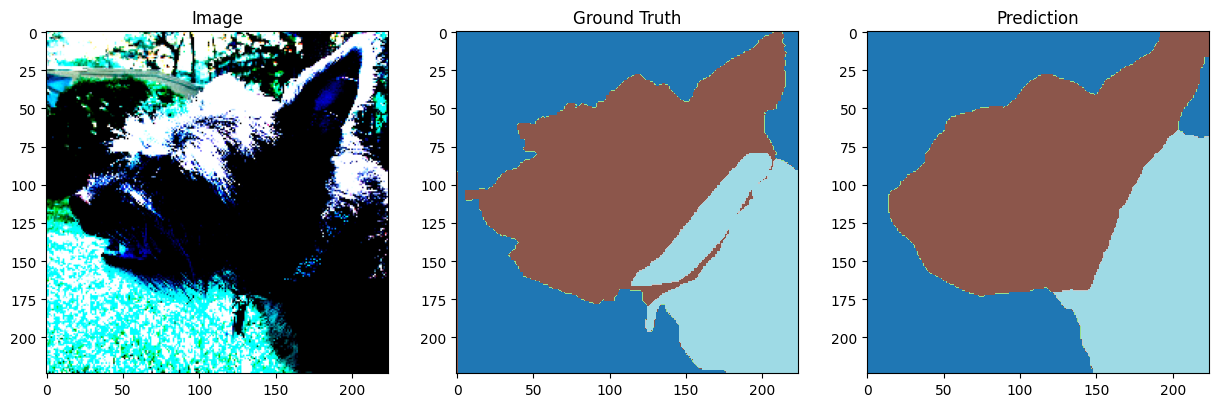

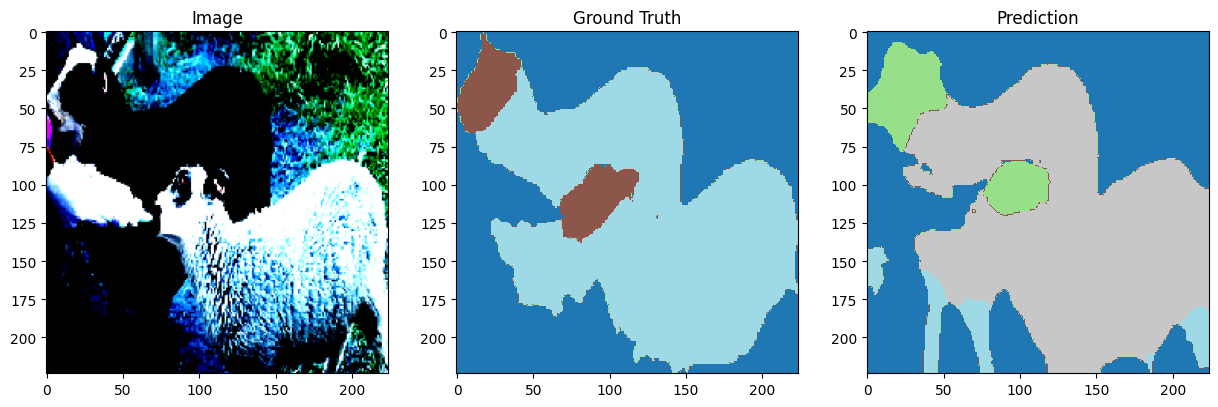

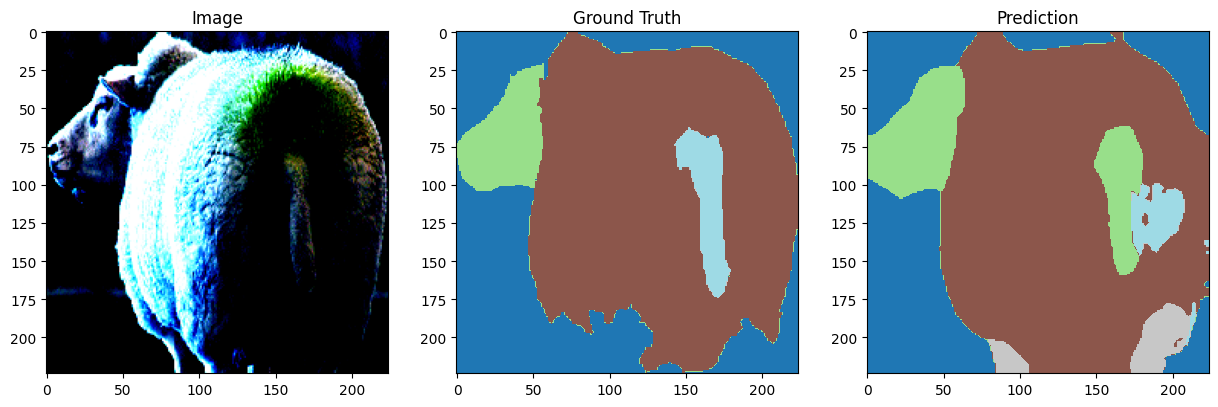

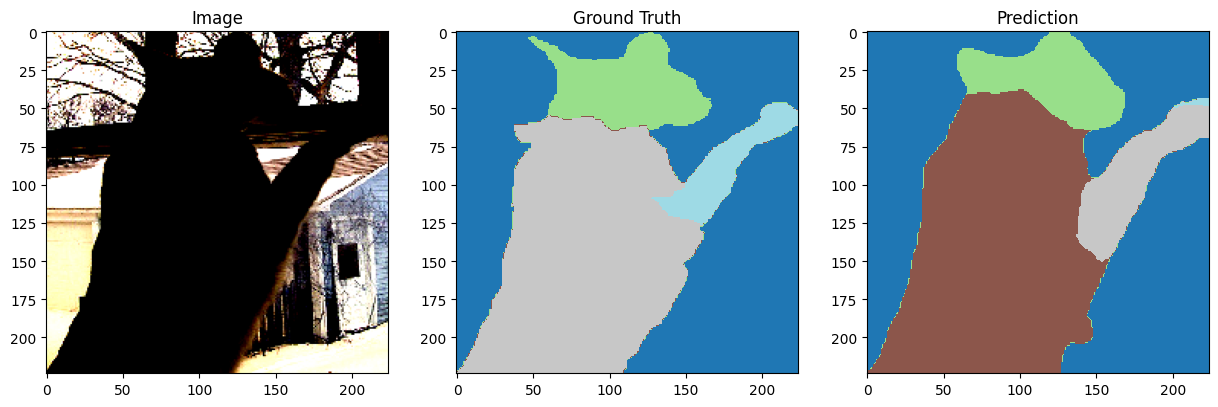

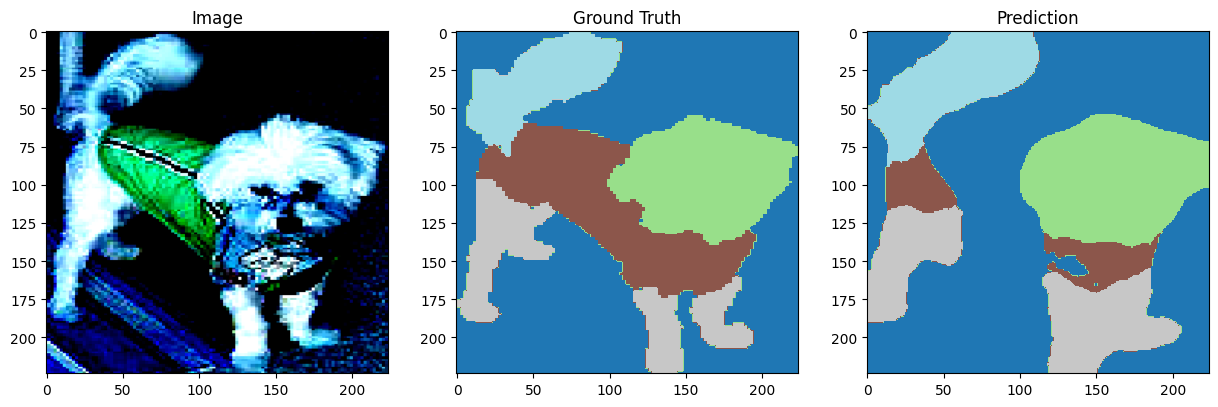

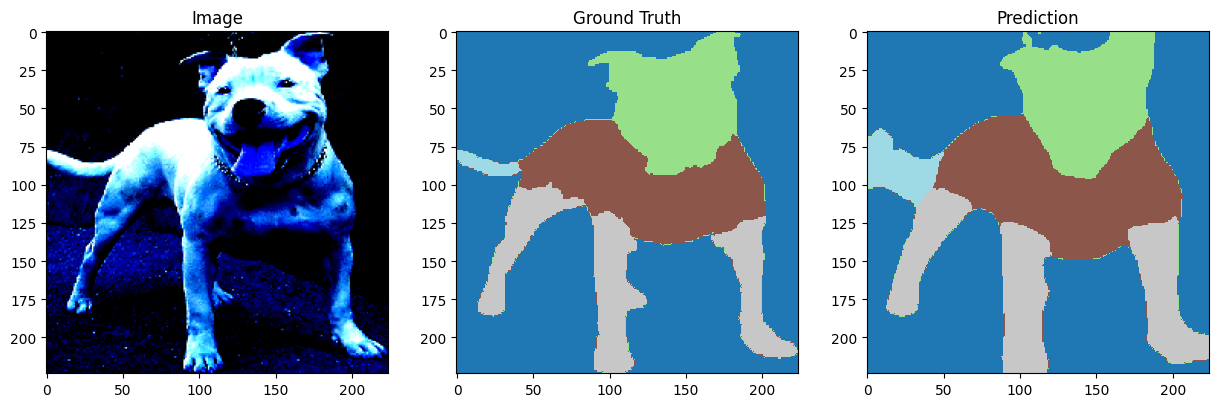

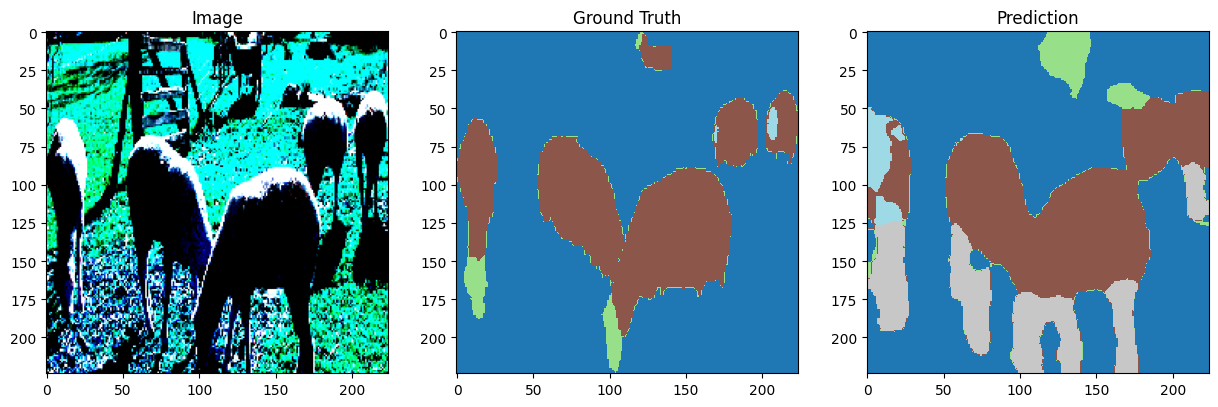

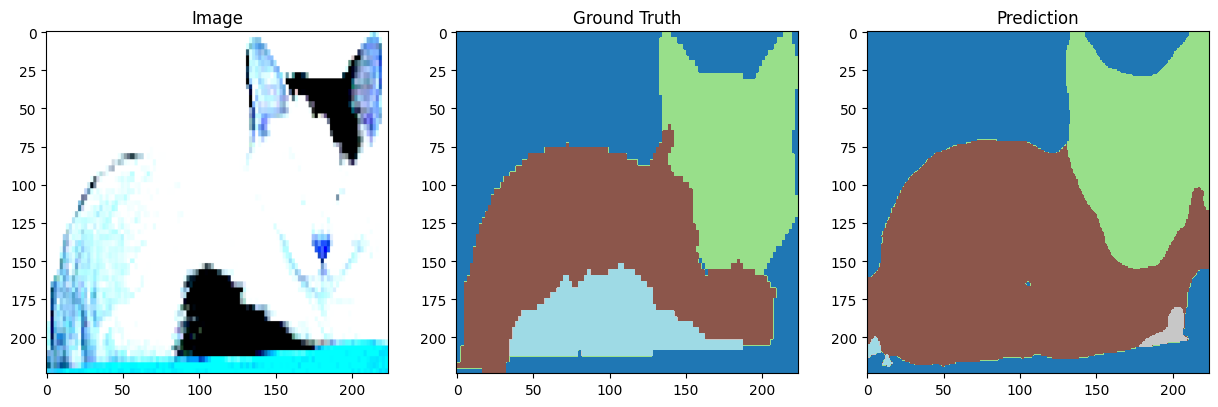

In [16]:
# Plotting function
def plot_images(image, masks, predicted_masks, num_images=1, color_map=None):
    indices = np.random.choice(range(len(image)), num_images, replace=False)
    for i, index in enumerate(indices):
        fig, axs = plt.subplots(1, 3, figsize=(15, 5))
        axs[0].imshow(np.transpose(image[index].numpy(), (1, 2, 0)), cmap='gray')
        axs[0].set_title("Image")
        axs[1].imshow(masks[index], cmap=color_map)
        axs[1].set_title("Ground Truth")
        axs[2].imshow(predicted_masks[index].cpu(), cmap=color_map)
        axs[2].set_title("Prediction")
        plt.show()

# Plot examples
color_map = plt.cm.get_cmap('tab20', 5)
plot_images(carry['image'], labels, preds, 8, color_map)

In [22]:
# Test Data Preparation for Submission
test_csv = '/kaggle/input/ai-dl-multiclass-segmentation/test_class.csv'
test_images_path = '/kaggle/input/ai-dl-multiclass-segmentation/TestImages'
test_data = pd.read_csv(test_csv)

def prepare_test_data(test_df, images_path):
    data = []
    for _, row in test_df.iterrows():
        img_path = os.path.join(images_path, row['ImageName'] + ".jpg")
        if os.path.exists(img_path):
            image = Image.open(img_path).convert("RGB")
           

In [ ]:
def prepare_test_data(test_df, images_path, model, device, save_path):
    """
    Prepares test data predictions and saves them in an Excel file.
    
    Args:
        test_df (pd.DataFrame): DataFrame containing test image information.
        images_path (str): Path to the directory containing test images.
        model (torch.nn.Module): Trained segmentation model.
        device (torch.device): Device to run the model on.
        save_path (str): Path to save the resulting Excel file.

    Returns:
        None
    """
    # Ensure the model is in evaluation mode
    model.eval()
    
    # Initialize a list to store the results
    results = []
    
    for _, row in test_df.iterrows():
        img_path = os.path.join(images_path, row['ImageName'] + ".jpg")
        
        if os.path.exists(img_path):
            # Read and preprocess the image
            image = Image.open(img_path).convert("RGB")
            image = np.array(image)
            image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_LINEAR)
            image_tensor = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).float().to(device)
            
            # Generate predictions
            with torch.no_grad():
                outputs = model(image_tensor)
                logits = outputs[0]
                preds = logits.softmax(dim=1).argmax(dim=1).cpu().numpy()[0]
            
            # Convert the prediction mask to RLE format
            rle = encode_rle(preds)
            
            # Append the results
            results.append({
                "ImageName": row['ImageName'],
                "Encoding": rle
            })
    
    # Create a DataFrame and save it as an Excel file
    results_df = pd.DataFrame(results)
    results_df.to_excel(save_path, index=False)
    print(f"Results saved to {save_path}")

def encode_rle(mask):
    """
    Encodes a mask as Run-Length Encoding (RLE).

    Args:
        mask (np.ndarray): Mask to encode.

    Returns:
        str: RLE string.
    """
    flat_mask = mask.flatten()
    rle = []
    prev = -1
    count = 0
    for i, val in enumerate(flat_mask):
        if val != prev:
            if prev != -1:
                rle.append(f"{start} {count}")
            prev = val
            start = i
            count = 1
        else:
            count += 1
    rle.append(f"{start} {count}")  # Append the last segment
    return " ".join(rle)

# Usage example:
prepare_test_data(
    test_df=test_data,
    images_path=test_images_path,
    model=model_ft,
    device=device,
    save_path="/kaggle/working/test_predictions.xlsx"
)
